In [21]:
# Importing the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# Installing openpyxl for reading Excel files
%pip install openpyxl
%pip install statsmodels
import statsmodels.formula.api as smf

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [22]:
# Settings for 9/11 analysis

event_name = '9/11'
event_date = pd.Timestamp('2001-09-01')

shock_start = pd.Timestamp('2001-09-01')
shock_end = pd.Timestamp('2001-09-01')

# Five historical years
base_start = pd.Timestamp('1996-09-01')
index_start = base_start

# Period shown in graphs
plot_start = pd.Timestamp('1999-09-01')
plot_end = pd.Timestamp('2003-09-01')

base_label = 'Sep 1996 - Aug 2001'

In [23]:
# Loading/reading the Excel dataset
df = pd.read_excel("Monthly_traffic_data_1992-current.xlsx")

In [25]:
# Filtering the Excel dataset
df = pd.read_excel(
    "Monthly_traffic_data_1992-current.xlsx",
    header=[7, 8]
)

data = df[
    [
        ('Unnamed: 0_level_0', 'Year'),
        ('Unnamed: 1_level_0', 'Month'),
        ('Passengers', 'Total*'),
        ('Air Transport Movements', 'Total')
    ]
].copy()

data.columns = ['Year', 'Month', 'Passengers', 'Flights']
data['Year'] = data['Year'].ffill()

months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

data = data[data['Month'].isin(months)].copy()

data['Year'] = pd.to_numeric(data['Year'], errors='coerce')
data = data.dropna(subset=['Year'])
data['Year'] = data['Year'].astype(int)

data['Date'] = pd.to_datetime(
    data['Year'].astype(str) + ' ' + data['Month'],
    format='%Y %B'
)

data = data.sort_values('Date').reset_index(drop=True)

# Additional columns for further analyses
data['Month_Num'] = data['Date'].dt.month

display(data.head())

display(data.head(15))

,Year,Month,Passengers,Flights,Date,Month_Num
0,1992,January,1149822.0,17671,1992-01-01,1
1,1992,February,1086979.0,16809,1992-02-01,2
2,1992,March,1276674.0,18452,1992-03-01,3
3,1992,April,1522522.0,19660,1992-04-01,4
4,1992,May,1742117.0,20758,1992-05-01,5


,Year,Month,Passengers,Flights,Date,Month_Num
0,1992,January,1149822.0,17671,1992-01-01,1
1,1992,February,1086979.0,16809,1992-02-01,2
2,1992,March,1276674.0,18452,1992-03-01,3
3,1992,April,1522522.0,19660,1992-04-01,4
4,1992,May,1742117.0,20758,1992-05-01,5
5,1992,June,1737275.0,20609,1992-06-01,6
6,1992,July,1979900.0,21995,1992-07-01,7
7,1992,August,2061036.0,21825,1992-08-01,8
8,1992,September,1867943.0,21053,1992-09-01,9
9,1992,October,1707752.0,21038,1992-10-01,10


In [26]:
# Baseline and index calculations

# Historical data before 9/11
before = data[
    (data['Date'] >= index_start) &
    (data['Date'] < shock_start)
].copy()

# Average per calendar month
base_pax = before.groupby('Month_Num')['Passengers'].mean()
base_flights = before.groupby('Month_Num')['Flights'].mean()

# Seasonal indices (baseline = 100)
data['Index_Pax'] = (
    data['Passengers'] / data['Month_Num'].map(base_pax) * 100
)

data['Index_Flights'] = (
    data['Flights'] / data['Month_Num'].map(base_flights) * 100
)

# Year-on-year percentage change
data['YoY'] = (
    data.groupby('Month_Num')['Passengers'].pct_change() * 100
)

# Select plotting period
window = data[
    (data['Date'] >= plot_start) &
    (data['Date'] <= plot_end)
].copy().reset_index(drop=True)

print('Historical months:', len(before))
display(window.head())

Historical months: 60


,Year,Month,Passengers,Flights,Date,Month_Num,Index_Pax,Index_Flights,YoY
0,1999,September,3467185.0,34411,1999-09-01,9,108.532021,107.085953,9.104672
1,1999,October,3449646.0,35126,1999-10-01,10,109.753597,107.144382,9.757837
2,1999,November,2802951.0,33183,1999-11-01,11,110.349039,109.422402,10.100341
3,1999,December,2462530.0,31521,1999-12-01,12,104.017515,106.744465,2.010060
4,2000,January,2490645.0,32537,2000-01-01,1,106.468906,107.553931,4.976317


In [39]:
# Consistent layout for all plots

colors = {
    'main': '#1f4e79',
    'second': '#e07b39',
    'good': '#2e8b57',
    'bad': '#c0392b',
    'grey': '#8c8c8c'
}

def make_figure(title, subtitle, ylabel, source='Schiphol'):
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.set_title(title, loc='left', fontsize=14,
                 fontweight='bold', pad=28)

    ax.text(0, 1.03, subtitle, transform=ax.transAxes,
            fontsize=10, color='#555555')

    ax.set_ylabel(ylabel)
    ax.grid(axis='y', color='#e6e6e6')
    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    fig.text(0.01, 0.01, 'Source:' + source,
             fontsize=8, color='#888888')

    return fig, ax


def mark_event(ax):
    ax.axvline(event_date, linestyle='--',
               color=colors['grey'], linewidth=1)

    ax.set_xlim(plot_start, plot_end)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def finish(ax, legend=True):
    if legend:
        ax.legend(loc='upper center',
                  bbox_to_anchor=(0.5, -0.1),
                  ncol=3, frameon=False)

    plt.tight_layout()
    plt.show()

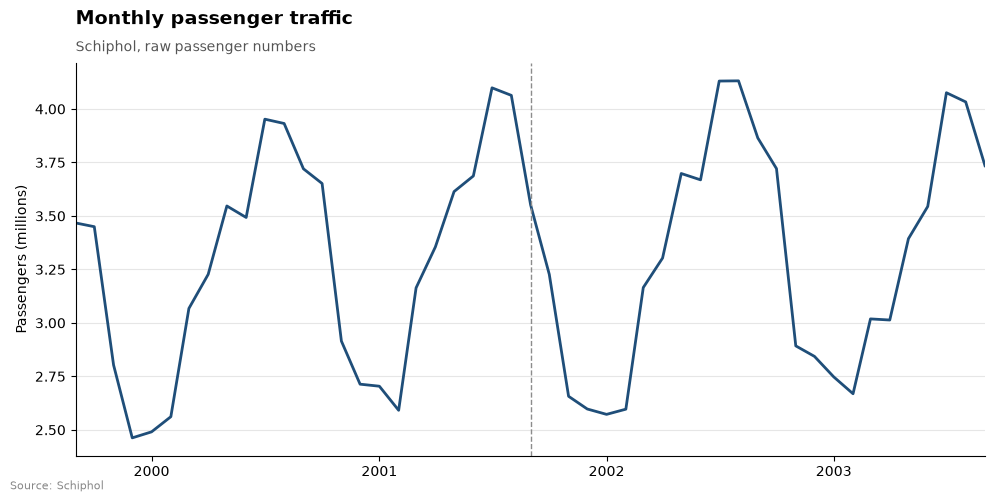

In [28]:
# Plot 1: Raw passenger data

fig, ax = make_figure(
    'Monthly passenger traffic',
    'Schiphol, raw passenger numbers',
    'Passengers (millions)'
)

ax.plot(
    window['Date'],
    window['Passengers'] / 1e6,
    color=colors['main'],
    linewidth=2,
    label='Passengers'
)

mark_event(ax)
finish(ax, legend=False)

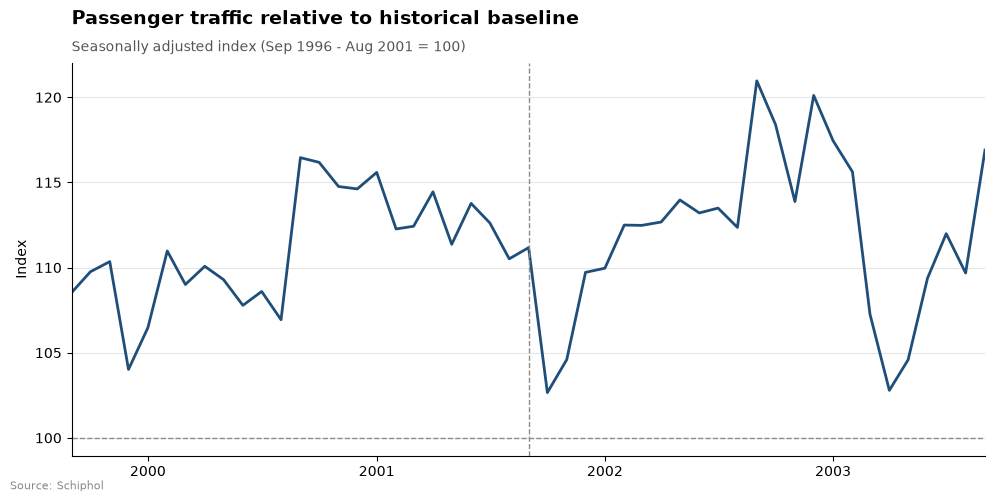

In [29]:
# Plot 2: Seasonal correction

fig, ax = make_figure(
    'Passenger traffic relative to historical baseline',
    'Seasonally adjusted index (' + base_label + ' = 100)',
    'Index'
)

ax.plot(
    window['Date'],
    window['Index_Pax'],
    color=colors['main'],
    linewidth=2,
    label='Passengers (index)'
)

# Historical baseline
ax.axhline(
    100,
    linestyle='--',
    color=colors['grey'],
    linewidth=1
)

mark_event(ax)
finish(ax, legend=False)

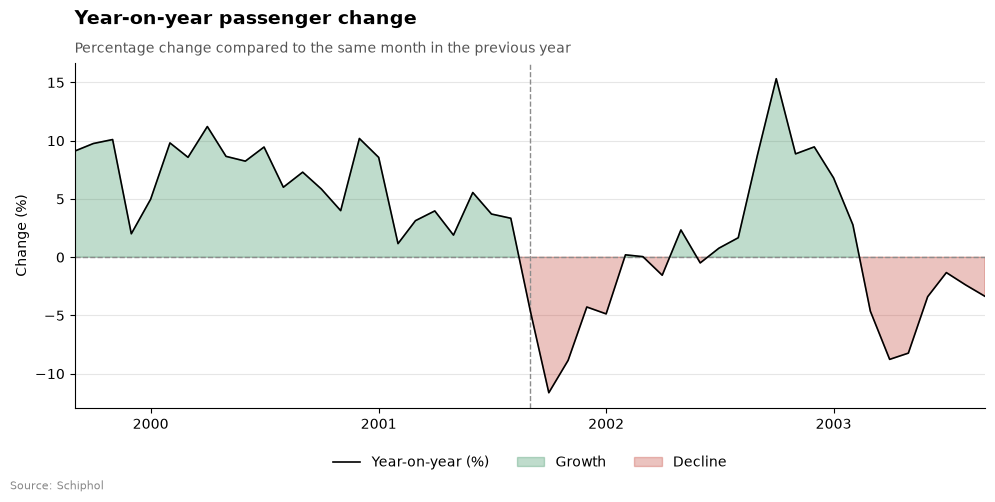

In [30]:
# Plot 3: Year-on-year passenger change

fig, ax = make_figure(
    'Year-on-year passenger change',
    'Percentage change compared to the same month in the previous year',
    'Change (%)'
)

dates = window['Date'].values
yoy = window['YoY'].values

# Plot year-on-year change
ax.plot(
    dates, yoy,
    color='black',
    linewidth=1.2,
    label='Year-on-year (%)',
    zorder=3
)

# Highlight positive growth
ax.fill_between(
    dates, yoy, 0,
    where=(yoy >= 0),
    color=colors['good'],
    alpha=0.3,
    interpolate=True,
    label='Growth'
)

# Highlight negative growth
ax.fill_between(
    dates, yoy, 0,
    where=(yoy < 0),
    color=colors['bad'],
    alpha=0.3,
    interpolate=True,
    label='Decline'
)

# Reference line at 0%
ax.axhline(
    0,
    linestyle='--',
    color=colors['grey'],
    linewidth=1
)

mark_event(ax)
finish(ax)

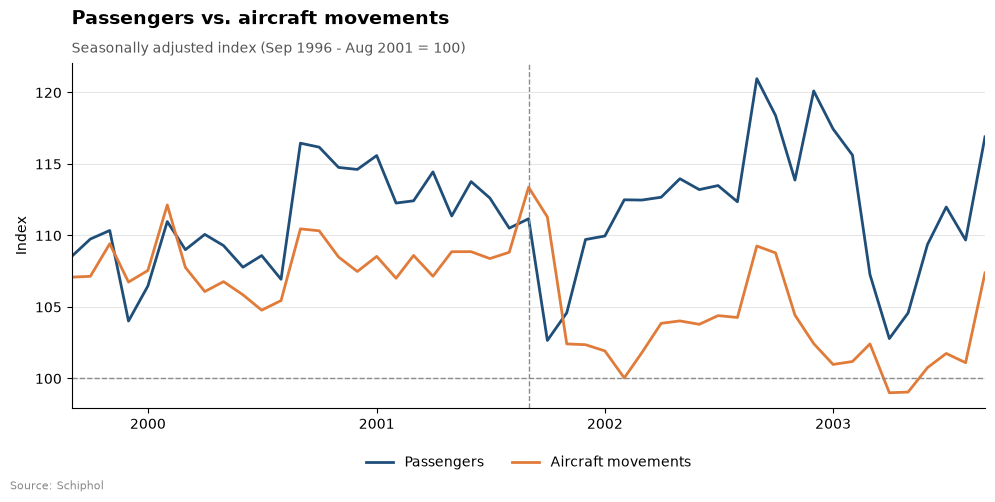

In [31]:
# Plot 4: Passengers vs. aircraft movements

fig, ax = make_figure(
    'Passengers vs. aircraft movements',
    'Seasonally adjusted index (' + base_label + ' = 100)',
    'Index'
)

# Passenger traffic
ax.plot(
    window['Date'],
    window['Index_Pax'],
    color=colors['main'],
    linewidth=2,
    label='Passengers'
)

# Aircraft movements
ax.plot(
    window['Date'],
    window['Index_Flights'],
    color=colors['second'],
    linewidth=2,
    label='Aircraft movements'
)

# Historical baseline
ax.axhline(
    100,
    linestyle='--',
    color=colors['grey'],
    linewidth=1
)

mark_event(ax)
finish(ax)

In [32]:
# Plot 5: Prediction model

n_growth_years = 5
last_normal_year = shock_start.year - 1  # 2000

def expected_passengers(year, month):

    # Last available year before the disruption
    anchor = min(year - 1, last_normal_year)

    # Historical growth rates for this calendar month
    growth_rows = data[
        (data['Month_Num'] == month) &
        (data['Year'] > anchor - n_growth_years) &
        (data['Year'] <= anchor)
    ]

    avg_growth = growth_rows['YoY'].mean() / 100

    # Passenger traffic in the reference year
    anchor_value = data[
        (data['Year'] == anchor) &
        (data['Month_Num'] == month)
    ]['Passengers'].iloc[0]

    # Predicted passenger traffic
    return anchor_value * (1 + avg_growth) ** (year - anchor)


# Calculate predictions and percentage deviations
window['Predicted'] = window.apply(
    lambda row: expected_passengers(
        row['Year'], row['Month_Num']
    ),
    axis=1
)

window['Deviation'] = (
    (window['Passengers'] - window['Predicted'])
    / window['Predicted']
) * 100

display(
    window[['Date', 'Passengers', 'Predicted', 'Deviation']].head()
)

,Date,Passengers,Predicted,Deviation
0,1999-09-01,3467185.0,3.457109e+06,0.291453
1,1999-10-01,3449646.0,3.447894e+06,0.050811
2,1999-11-01,2802951.0,2.844488e+06,-1.460261
3,1999-12-01,2462530.0,2.675347e+06,-7.954748
4,2000-01-01,2490645.0,2.605613e+06,-4.412308


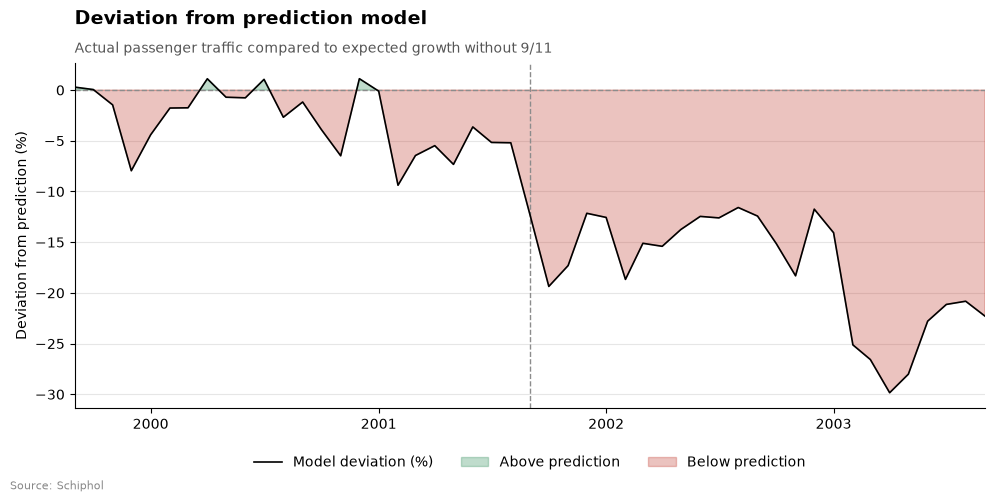

In [33]:
# Plot 5: Deviation from prediction model

fig, ax = make_figure(
    'Deviation from prediction model',
    'Actual passenger traffic compared to expected growth without 9/11',
    'Deviation from prediction (%)'
)

dates = window['Date'].values
devs = window['Deviation'].values

# Plot percentage deviation
ax.plot(
    dates, devs,
    color='black',
    linewidth=1.2,
    label='Model deviation (%)',
    zorder=3
)

# Positive deviations
ax.fill_between(
    dates, devs, 0,
    where=(devs >= 0),
    color=colors['good'],
    alpha=0.3,
    interpolate=True,
    label='Above prediction'
)

# Negative deviations
ax.fill_between(
    dates, devs, 0,
    where=(devs < 0),
    color=colors['bad'],
    alpha=0.3,
    interpolate=True,
    label='Below prediction'
)

# Reference line at 0%
ax.axhline(
    0,
    linestyle='--',
    color=colors['grey'],
    linewidth=1
)

mark_event(ax)
finish(ax)

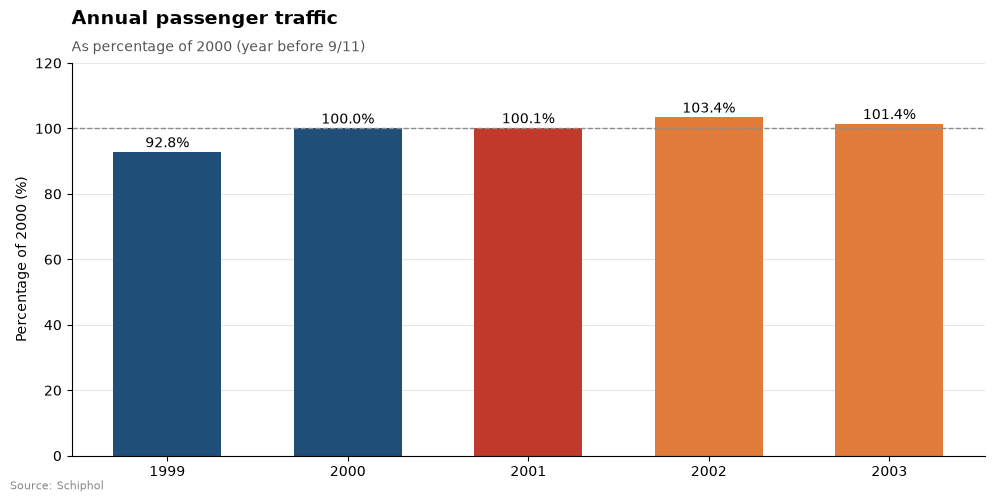

In [34]:
# Plot 6: Annual passenger comparison

# Reference year before 9/11
base_year = 2000

# Select annual passenger data
annual = data[
    (data['Year'] >= 1999) &
    (data['Year'] <= 2003)
].groupby('Year')['Passengers'].sum()

# Calculate percentage relative to 2000
percentages = annual / annual[base_year] * 100

# Create figure
fig, ax = make_figure(
    'Annual passenger traffic',
    'As percentage of 2000 (year before 9/11)',
    'Percentage of 2000 (%)'
)

# Bar colors
bar_colors = []

for year in percentages.index:
    if year < 2001:
        bar_colors.append(colors['main'])
    elif year == 2001:
        bar_colors.append(colors['bad'])
    else:
        bar_colors.append(colors['second'])

# Plot bars
bars = ax.bar(
    percentages.index,
    percentages.values,
    color=bar_colors,
    width=0.6
)

# Add percentage labels
for bar, value in zip(bars, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1.5,
        f'{value:.1f}%',
        ha='center',
        fontsize=10
    )

# Reference line
ax.axhline(
    100,
    linestyle='--',
    color=colors['grey'],
    linewidth=1
)

ax.set_ylim(0, max(120, percentages.max() + 10))
ax.set_xticks(percentages.index)

finish(ax, legend=False)

In [35]:
## 4. Validation: Social safety after 9/11

In [36]:
# Load Gallup survey data for 9/11 validation

gallup = pd.read_excel(
    '911_veiligheidsgevoel_validatiedata.xlsx',
    sheet_name='Gallup_flying'
)

# Convert dates to datetime
gallup['Survey_date'] = pd.to_datetime(gallup['Survey_date'])

# Display the data
display(gallup)

,Survey_date,Survey_period,Less_willing_to_fly_pct,Less_willing_to_travel_overseas_pct,Respondents,Source_URL
0,2001-09-14,14–15 Sep 2001,43,48,US adults,https://news.gallup.com/poll/6790/Americans-Ch...
1,2002-03-08,8–9 Mar 2002,33,45,US adults,https://news.gallup.com/poll/6790/Americans-Ch...
2,2002-05-28,28–29 May 2002,27,43,US adults,https://news.gallup.com/poll/6790/Americans-Ch...
3,2002-09-02,2–4 Sep 2002,33,47,US adults,https://news.gallup.com/poll/6790/Americans-Ch...


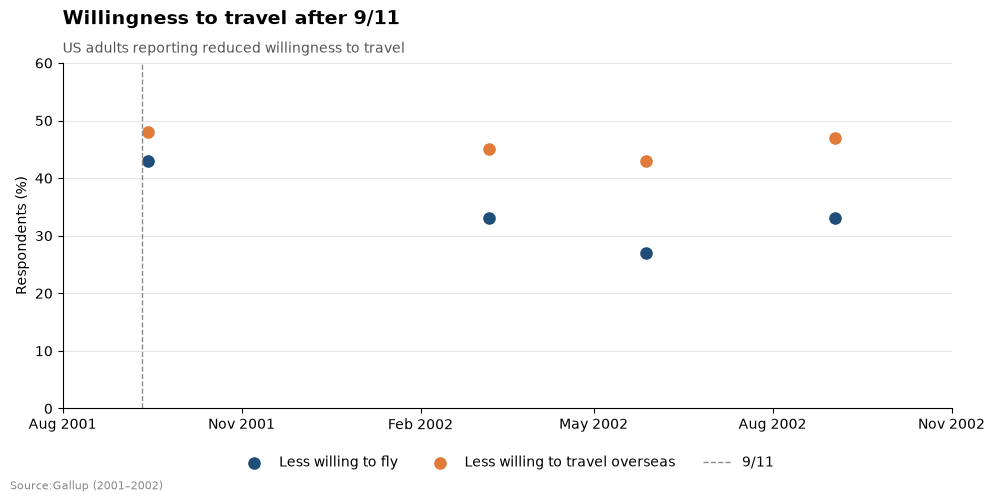

In [40]:
# Plot 7: Social safety after 9/11

fig, ax = make_figure(
    'Willingness to travel after 9/11',
    'US adults reporting reduced willingness to travel',
    'Respondents (%)',
    source='Gallup (2001–2002)'
)

# Less willing to fly
ax.scatter(
    gallup['Survey_date'],
    gallup['Less_willing_to_fly_pct'],
    color=colors['main'],
    s=65,
    label='Less willing to fly'
)

# Less willing to travel overseas
ax.scatter(
    gallup['Survey_date'],
    gallup['Less_willing_to_travel_overseas_pct'],
    color=colors['second'],
    s=65,
    label='Less willing to travel overseas'
)

# Mark 9/11
ax.axvline(
    pd.Timestamp('2001-09-11'),
    color=colors['grey'],
    linestyle='--',
    linewidth=1,
    label='9/11'
)

# Axis settings
ax.set_ylim(0, 60)
ax.set_xlim(
    pd.Timestamp('2001-08-01'),
    pd.Timestamp('2002-11-01')
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

finish(ax)